Starting Part A: RNN Sentiment Analysis
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of training reviews: 25000
Number of test reviews: 25000
Label of the first training review: 1
Length of the first training review: 218
First 20 integer IDs of that review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
x_train shape after padding: (25000, 200)
x_test shape after padding: (25000, 200)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 102ms/step - accuracy: 0.5922 - loss: 0.6751 - val_accuracy: 0.6576 - val_loss: 0.6252
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.7982 - loss: 0.4538 - val_accuracy: 0.7996 - val_loss: 0.4652
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 90ms/step - accuracy: 0.9019 - loss: 0.2521 - val_accuracy: 0.8074 - val_loss: 0.4343
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.8114 - loss: 0.4396
RNN Test Loss: 0.4396
RNN Test Accuracy: 0.8114


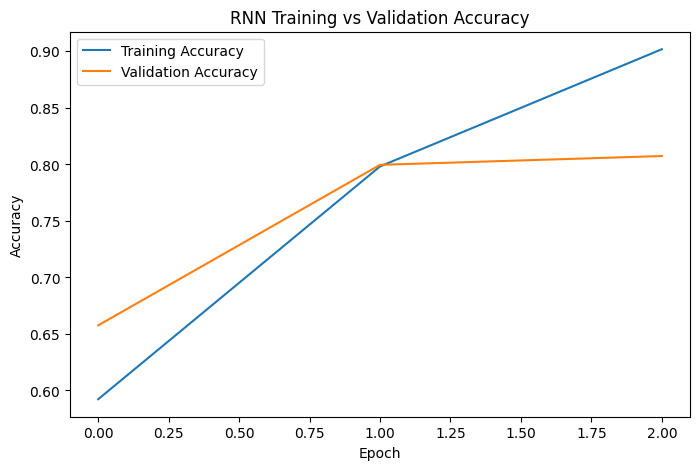


Starting Part B: CNN Image Classification
   475136/170498071 ━━━━━━━━━━━━━━━━━━━━ 1:28:06 31us/step

In [ ]:
"""
Deep Learning Task Script: RNN and CNN
- Part A: Movie-review sentiment classification with the IMDB dataset.
- Part B: Image classification with the CIFAR-10 dataset.
"""

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb, cifar10
from tensorflow.keras.preprocessing.sequence import pad_sequences

# =====================================================================
# PART A — RNN for Sentiment Analysis (IMDB Dataset)
# =====================================================================

print("=========================================")
print("Starting Part A: RNN Sentiment Analysis")
print("=========================================")

# TODO A2: Load the IMDB dataset (top 10,000 frequent words)
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=10000)

# TODO A3: Inspect the dataset
print("Number of training reviews:", len(x_train))
print("Number of test reviews:", len(x_test))
print("Label of the first training review:", y_train[0])
print("Length of the first training review:", len(x_train[0]))
print("First 20 integer IDs of that review:", x_train[0][:20])

# TODO A4: Pad the reviews to a length of 200
x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)
print("x_train shape after padding:", x_train.shape)
print("x_test shape after padding:", x_test.shape)

# TODO A5: Build the RNN model
rnn_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=10000, output_dim=32, mask_zero=True),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
rnn_model.summary()

# TODO A6: Compile the model
rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# TODO A7: Train the model
history_rnn = rnn_model.fit(
    x_train, y_train,
    epochs=3,
    validation_split=0.2,
    batch_size=64
)

# TODO A8: Evaluate on the test data
test_loss_rnn, test_acc_rnn = rnn_model.evaluate(x_test, y_test)
print(f"RNN Test Loss: {test_loss_rnn:.4f}")
print(f"RNN Test Accuracy: {test_acc_rnn:.4f}")

# TODO A9: Plot training vs validation accuracy for RNN
plt.figure(figsize=(8, 5))
plt.plot(history_rnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_rnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("RNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# =====================================================================
# PART B — CNN for Image Classification (CIFAR-10 Dataset)
# =====================================================================

print("\n=========================================")
print("Starting Part B: CNN Image Classification")
print("=========================================")

# TODO B2: Load CIFAR-10
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = cifar10.load_data()
print("x_train shape:", x_train_cifar.shape)
print("y_train shape:", y_train_cifar.shape)
print("x_test shape:", x_test_cifar.shape)
print("y_test shape:", y_test_cifar.shape)

# Class names for CIFAR-10
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# TODO B3: Display one training image
plt.figure(figsize=(3, 3))
plt.imshow(x_train_cifar[0])
plt.axis("off")
plt.title(f"Label: {class_names[y_train_cifar[0][0]]}")
plt.show()
print("Label index:", y_train_cifar[0][0])
print("Class name:", class_names[y_train_cifar[0][0]])

# TODO B4: Normalize image pixels
x_train_cifar = x_train_cifar.astype("float32") / 255.0
x_test_cifar = x_test_cifar.astype("float32") / 255.0

# TODO B5: Build the CNN
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
cnn_model.summary()

# TODO B6: Compile the CNN
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# TODO B7: Train the CNN
history_cnn = cnn_model.fit(
    x_train_cifar, y_train_cifar,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# TODO B8: Evaluate the CNN
test_loss_cnn, test_acc_cnn = cnn_model.evaluate(x_test_cifar, y_test_cifar)
print(f"CNN Test Loss: {test_loss_cnn:.4f}")
print(f"CNN Test Accuracy: {test_acc_cnn:.4f}")

# TODO B9: Predict one test image
predictions = cnn_model.predict(x_test_cifar[:1])
pred_idx = np.argmax(predictions[0])
actual_idx = y_test_cifar[0][0]
print(f"Predicted: {class_names[pred_idx]} | Actual: {class_names[actual_idx]}")

plt.figure(figsize=(3, 3))
plt.imshow(x_test_cifar[0])
plt.title(f"Pred: {class_names[pred_idx]} | Actual: {class_names[actual_idx]}")
plt.axis("off")
plt.show()

# TODO B10: Plot training vs validation accuracy for CNN
plt.figure(figsize=(8, 5))
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
